In [1]:
%run ./notebook_setup.py

Project Root: /mnt/d/Projects/ISRO_Exoplanet
Source Dir: /mnt/d/Projects/ISRO_Exoplanet/src
Project structure verified.


/home/darxsouls/miniconda3/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [4]:
import sys

print(sys.executable)
print(sys.version)

/usr/bin/python3
3.10.12 (main, Mar  3 2026, 11:56:32) [GCC 11.4.0]


In [2]:
import lightkurve as lk

# Search TESS light curves
search_result = lk.search_lightcurve(
    "TIC 25155310",
    mission="TESS"
)

print(search_result)

SearchResult containing 220 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 01 2018   SPOC     120    25155310      0.0
  1 TESS Sector 02 2018   SPOC     120    25155310      0.0
  2 TESS Sector 03 2018   SPOC     120    25155310      0.0
  3 TESS Sector 04 2018   SPOC     120    25155310      0.0
  4 TESS Sector 05 2018   SPOC     120    25155310      0.0
  5 TESS Sector 06 2018   SPOC     120    25155310      0.0
  6 TESS Sector 07 2019   SPOC     120    25155310      0.0
  7 TESS Sector 08 2019   SPOC     120    25155310      0.0
  8 TESS Sector 09 2019   SPOC     120    25155310      0.0
...            ...  ...    ...     ...         ...      ...
210 TESS Sector 02 2018   TGLC    1800    25155310      0.0
211 TESS Sector 03 2018   TGLC    1800    25155310      0.0
212 TESS Sector 04 2018   TGLC    1800    25155310      

In [2]:
lc = search_result.download()

print(lc)

       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
1325.2966258808235  9.2627041e+03 ...  2.9971417e-02 -6.6027217e-02
1325.2980147804474  9.2711973e+03 ... -4.2239105e-04 -1.0025273e-01
 1325.299403680013  9.2906729e+03 ... -1.2138215e-03 -1.0391606e-01
1325.3007925795785  9.2628174e+03 ... -2.9799975e-03 -1.1566762e-01
1325.3021814792023  9.2777139e+03 ... -9.8572923e-03 -1.1535366e-01
 1325.303570378768  9.2604170e+03 ... -1.0768156e-02 -1.1588433e-01
1325.3049592783916  9.2684199e+03 ... -6.7567211e-03 -1.2002597e-01
1325.3063481780152  9.2672148e+03 ... -8.2860291e-03 -1.1578123e-01
 1325.307737077639  9.2526143e+03 ... -1.2014245e-02 -1.1912200e-01
               ...            ... ...            ...            ...
1353.1648095155513  9.2582285e+03 ... -1.6124731e-02 -5.4954281e-03
1353.1661984014393  9.2979814e+03 ... -1.2574126

/home/darxsouls/miniconda3/lib/python3.12/site-packages/lightkurve/search.py:421: LightkurveWarning: Warning: 220 files available to download. Only the first file has been downloaded. Please use `download_all()` or specify additional criteria (e.g. quarter, campaign, or sector) to limit your search.
  warnings.warn(


In [3]:
print(lc.columns)

<TableColumns names=('time','flux','flux_err','timecorr','cadenceno','centroid_col','centroid_row','sap_flux','sap_flux_err','sap_bkg','sap_bkg_err','pdcsap_flux','pdcsap_flux_err','quality','psf_centr1','psf_centr1_err','psf_centr2','psf_centr2_err','mom_centr1','mom_centr1_err','mom_centr2','mom_centr2_err','pos_corr1','pos_corr2')>


In [4]:
print(lc.to_table().colnames)

['time', 'flux', 'flux_err', 'timecorr', 'cadenceno', 'centroid_col', 'centroid_row', 'sap_flux', 'sap_flux_err', 'sap_bkg', 'sap_bkg_err', 'pdcsap_flux', 'pdcsap_flux_err', 'quality', 'psf_centr1', 'psf_centr1_err', 'psf_centr2', 'psf_centr2_err', 'mom_centr1', 'mom_centr1_err', 'mom_centr2', 'mom_centr2_err', 'pos_corr1', 'pos_corr2']


In [5]:
from astropy.io import fits

fits_path = lc.filename

hdul = fits.open(fits_path)

hdul.info()

Filename: /home/darxsouls/.lightkurve/cache/mastDownload/TESS/tess2018206045859-s0001-0000000025155310-0120-s/tess2018206045859-s0001-0000000025155310-0120-s_lc.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      44   ()      
  1  LIGHTCURVE    1 BinTableHDU    167   20076R x 20C   [D, E, J, E, E, E, E, E, E, J, D, E, D, E, D, E, D, E, E, E]   
  2  APERTURE      1 ImageHDU        49   (11, 11)   int32   


In [6]:
data = hdul[1].data

print(data.columns)

ColDefs(
    name = 'TIME'; format = 'D'; unit = 'BJD - 2457000, days'; disp = 'D14.7'
    name = 'TIMECORR'; format = 'E'; unit = 'd'; disp = 'E14.7'
    name = 'CADENCENO'; format = 'J'; disp = 'I10'
    name = 'SAP_FLUX'; format = 'E'; unit = 'e-/s'; disp = 'E14.7'
    name = 'SAP_FLUX_ERR'; format = 'E'; unit = 'e-/s'; disp = 'E14.7'
    name = 'SAP_BKG'; format = 'E'; unit = 'e-/s'; disp = 'E14.7'
    name = 'SAP_BKG_ERR'; format = 'E'; unit = 'e-/s'; disp = 'E14.7'
    name = 'PDCSAP_FLUX'; format = 'E'; unit = 'e-/s'; disp = 'E14.7'
    name = 'PDCSAP_FLUX_ERR'; format = 'E'; unit = 'e-/s'; disp = 'E14.7'
    name = 'QUALITY'; format = 'J'; disp = 'B16.16'
    name = 'PSF_CENTR1'; format = 'D'; unit = 'pixel'; disp = 'F10.5'
    name = 'PSF_CENTR1_ERR'; format = 'E'; unit = 'pixel'; disp = 'E14.7'
    name = 'PSF_CENTR2'; format = 'D'; unit = 'pixel'; disp = 'F10.5'
    name = 'PSF_CENTR2_ERR'; format = 'E'; unit = 'pixel'; disp = 'E14.7'
    name = 'MOM_CENTR1'; format = 'D'; u

In [7]:
for col in data.columns:
    print(col.name)

TIME
TIMECORR
CADENCENO
SAP_FLUX
SAP_FLUX_ERR
SAP_BKG
SAP_BKG_ERR
PDCSAP_FLUX
PDCSAP_FLUX_ERR
QUALITY
PSF_CENTR1
PSF_CENTR1_ERR
PSF_CENTR2
PSF_CENTR2_ERR
MOM_CENTR1
MOM_CENTR1_ERR
MOM_CENTR2
MOM_CENTR2_ERR
POS_CORR1
POS_CORR2


In [8]:
import pandas as pd

required_cols = [
    "TIME",
    "SAP_FLUX",
    "SAP_FLUX_ERR",
    "PDCSAP_FLUX",
    "PDCSAP_FLUX_ERR",
    "QUALITY",
    "MOM_CENTR1",
    "MOM_CENTR2"
]

df = pd.DataFrame()

for col in required_cols:
    df[col] = data[col]

print(df.head())

          TIME     SAP_FLUX  SAP_FLUX_ERR  PDCSAP_FLUX  PDCSAP_FLUX_ERR  \
0  1325.295237  8370.004883     11.012258          NaN              NaN   
1  1325.296626  8426.264648     11.040674  9262.704102        12.471729   
2  1325.298015  8449.153320     11.044871  9271.197266        12.476470   
3  1325.299404  8466.763672     11.064793  9290.672852        12.498974   
4  1325.300793  8442.092773     11.050729  9262.817383        12.483087   

   QUALITY   MOM_CENTR1  MOM_CENTR2  
0        8  1623.905191  393.390861  
1        0  1623.851189  393.341453  
2        0  1623.826405  393.313301  
3        0  1623.826744  393.309616  
4        0  1623.825748  393.300314  


In [11]:
import numpy as np

for col in df.columns:
    df[col] = np.asarray(df[col], dtype=df[col].dtype.newbyteorder('='))

In [14]:
df_clean = pd.DataFrame({
    "TIME": np.array(data["TIME"], dtype=np.float64),

    "SAP_FLUX": np.array(data["SAP_FLUX"], dtype=np.float32),
    "SAP_FLUX_ERR": np.array(data["SAP_FLUX_ERR"], dtype=np.float32),

    "PDCSAP_FLUX": np.array(data["PDCSAP_FLUX"], dtype=np.float32),
    "PDCSAP_FLUX_ERR": np.array(data["PDCSAP_FLUX_ERR"], dtype=np.float32),

    "QUALITY": np.array(data["QUALITY"], dtype=np.int32),

    "MOM_CENTR1": np.array(data["MOM_CENTR1"], dtype=np.float32),
    "MOM_CENTR2": np.array(data["MOM_CENTR2"], dtype=np.float32),
})

In [17]:
print(df.dtypes)

TIME               float64
SAP_FLUX           float32
SAP_FLUX_ERR       float32
PDCSAP_FLUX        float32
PDCSAP_FLUX_ERR    float32
QUALITY              int32
MOM_CENTR1         float64
MOM_CENTR2         float64
dtype: object


In [18]:
df.to_parquet(
    "tic_25155310.parquet",
    index=False
)

In [19]:
header = hdul[0].header

metadata = {
    "TICID": header.get("TICID"),
    "SECTOR": header.get("SECTOR"),
    "CAMERA": header.get("CAMERA"),
    "CCD": header.get("CCD"),
    "TMAG": header.get("TESSMAG"),
    "RA": header.get("RA_OBJ"),
    "DEC": header.get("DEC_OBJ")
}

print(metadata)

{'TICID': 25155310, 'SECTOR': 1, 'CAMERA': 4, 'CCD': 1, 'TMAG': 10.61030006, 'RA': 63.3739396231274, 'DEC': -69.226822697583}


In [20]:
import json

with open("tic_25155310_meta.json", "w") as f:
    json.dump(metadata, f, indent=4)

In [21]:
tic_ids = [
    25155310,
    307210830,
    260128333
]

for tic in tic_ids:

    try:

        search = lk.search_lightcurve(
            f"TIC {tic}",
            mission="TESS"
        )

        lc = search.download()

        print(f"Downloaded TIC {tic}")

    except Exception as e:

        print(f"Failed {tic}: {e}")

/home/darxsouls/miniconda3/lib/python3.12/site-packages/lightkurve/search.py:421: LightkurveWarning: Warning: 220 files available to download. Only the first file has been downloaded. Please use `download_all()` or specify additional criteria (e.g. quarter, campaign, or sector) to limit your search.
  warnings.warn(


Downloaded TIC 25155310


/home/darxsouls/miniconda3/lib/python3.12/site-packages/lightkurve/search.py:421: LightkurveWarning: Warning: 142 files available to download. Only the first file has been downloaded. Please use `download_all()` or specify additional criteria (e.g. quarter, campaign, or sector) to limit your search.
  warnings.warn(


Downloaded TIC 307210830


/home/darxsouls/miniconda3/lib/python3.12/site-packages/lightkurve/search.py:421: LightkurveWarning: Warning: 209 files available to download. Only the first file has been downloaded. Please use `download_all()` or specify additional criteria (e.g. quarter, campaign, or sector) to limit your search.
  warnings.warn(


Downloaded TIC 260128333


In [13]:
from ingestion.download_tess import download_tess_target

from config import (
    PLANET_FITS_DIR,
    PLANET_PARQUET_DIR,
    PLANET_METADATA_DIR
)

/home/darxsouls/miniconda3/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [14]:
download_tess_target(
    tic_id=25155310,

    fits_dir=PLANET_FITS_DIR,

    parquet_dir=PLANET_PARQUET_DIR,

    metadata_dir=PLANET_METADATA_DIR
)

Saved TIC 25155310


{'fits': PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/fits/TIC_25155310.fits'),
 'parquet': PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/parquet/TIC_25155310.parquet'),
 'metadata': PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/metadata/TIC_25155310.json')}

In [15]:
from config import *

print(list(PLANET_FITS_DIR.glob("*")))
print(list(PLANET_PARQUET_DIR.glob("*")))
print(list(PLANET_METADATA_DIR.glob("*")))

[PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/fits/TIC_25155310.fits')]
[PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/parquet/TIC_25155310.parquet')]
[PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/metadata/TIC_25155310.json')]


In [16]:
import json

meta_file = next(
    PLANET_METADATA_DIR.glob("*.json")
)

with open(meta_file) as f:
    metadata = json.load(f)

metadata

{'TICID': 25155310,
 'SECTOR': 1,
 'CAMERA': 4,
 'CCD': 1,
 'TMAG': 10.61030006,
 'RA': 63.3739396231274,
 'DEC': -69.226822697583}

In [17]:
import pandas as pd

parquet_file = next(
    PLANET_PARQUET_DIR.glob("*.parquet")
)

df = pd.read_parquet(
    parquet_file
)

df.head()

,TIME,SAP_FLUX,SAP_FLUX_ERR,PDCSAP_FLUX,PDCSAP_FLUX_ERR,QUALITY,PSF_CENTR1,PSF_CENTR2,MOM_CENTR1,MOM_CENTR2
0,1325.295237,8370.004883,11.012258,NaN,NaN,8,NaN,NaN,1623.905151,393.390869
1,1325.296626,8426.264648,11.040674,9262.704102,12.471729,0,NaN,NaN,1623.851196,393.341461
2,1325.298015,8449.153320,11.044871,9271.197266,12.476470,0,NaN,NaN,1623.826416,393.313293
3,1325.299404,8466.763672,11.064793,9290.672852,12.498974,0,NaN,NaN,1623.826782,393.309601
4,1325.300793,8442.092773,11.050729,9262.817383,12.483087,0,NaN,NaN,1623.825806,393.300323


In [18]:
print(df.columns)

Index(['TIME', 'SAP_FLUX', 'SAP_FLUX_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR',
       'QUALITY', 'PSF_CENTR1', 'PSF_CENTR2', 'MOM_CENTR1', 'MOM_CENTR2'],
      dtype='object')


In [22]:
print(df["TIME"].min())
print(df["TIME"].max())

1325.295236981258
1353.17730948808


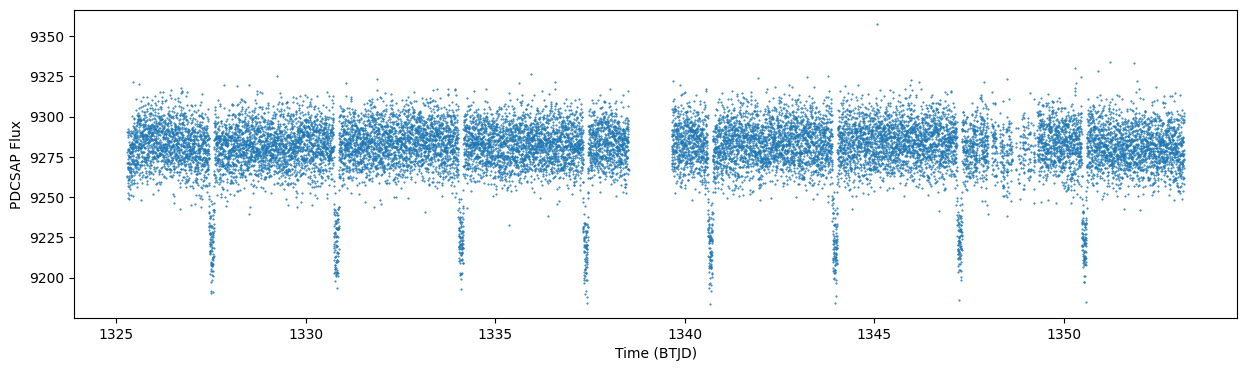

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,4))

plt.plot(
    df["TIME"],
    df["PDCSAP_FLUX"],
    ".",
    markersize=1
)

plt.xlabel("Time (BTJD)")
plt.ylabel("PDCSAP Flux")

plt.show()

In [32]:
from astropy.io import fits

fits_file = next(
    PLANET_FITS_DIR.glob("*.fits")
)

hdul = fits.open(
    fits_file
)

header = hdul[0].header

print(header["TICID"])
print(header["SECTOR"])
print(header["CAMERA"])
print(header["CCD"])
# print(header["TMAG"])
# print(header["RA"])
# print(header["DEC"])


25155310
1
4
1


In [28]:
import json

meta_file = next(
    PLANET_METADATA_DIR.glob("*.json")
)

with open(meta_file) as f:
    metadata = json.load(f)

metadata

{'TICID': 25155310,
 'SECTOR': 1,
 'CAMERA': 4,
 'CCD': 1,
 'TMAG': 10.61030006,
 'RA': 63.3739396231274,
 'DEC': -69.226822697583}

In [25]:
print(df.dtypes)

TIME               float64
SAP_FLUX           float32
SAP_FLUX_ERR       float32
PDCSAP_FLUX        float32
PDCSAP_FLUX_ERR    float32
QUALITY              int32
PSF_CENTR1         float32
PSF_CENTR2         float32
MOM_CENTR1         float32
MOM_CENTR2         float32
dtype: object


In [26]:
print(df.shape)

print(df.columns)

print(df.dtypes)

df.head()

(20076, 10)
Index(['TIME', 'SAP_FLUX', 'SAP_FLUX_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR',
       'QUALITY', 'PSF_CENTR1', 'PSF_CENTR2', 'MOM_CENTR1', 'MOM_CENTR2'],
      dtype='object')
TIME               float64
SAP_FLUX           float32
SAP_FLUX_ERR       float32
PDCSAP_FLUX        float32
PDCSAP_FLUX_ERR    float32
QUALITY              int32
PSF_CENTR1         float32
PSF_CENTR2         float32
MOM_CENTR1         float32
MOM_CENTR2         float32
dtype: object


,TIME,SAP_FLUX,SAP_FLUX_ERR,PDCSAP_FLUX,PDCSAP_FLUX_ERR,QUALITY,PSF_CENTR1,PSF_CENTR2,MOM_CENTR1,MOM_CENTR2
0,1325.295237,8370.004883,11.012258,NaN,NaN,8,NaN,NaN,1623.905151,393.390869
1,1325.296626,8426.264648,11.040674,9262.704102,12.471729,0,NaN,NaN,1623.851196,393.341461
2,1325.298015,8449.153320,11.044871,9271.197266,12.476470,0,NaN,NaN,1623.826416,393.313293
3,1325.299404,8466.763672,11.064793,9290.672852,12.498974,0,NaN,NaN,1623.826782,393.309601
4,1325.300793,8442.092773,11.050729,9262.817383,12.483087,0,NaN,NaN,1623.825806,393.300323


In [36]:
print(df["TIME"].min())
print(df["TIME"].max())

1325.295236981258
1353.17730948808


In [3]:
# from ingestion.download_tess import download_tess_target
from ingestion.download_tess import download_multiple_targets


from config import *

In [4]:
planet_tics = [

    25155310,
    38846515,
    149603524,
    261136679
]

In [5]:
download_multiple_targets(

    tic_ids=planet_tics,

    fits_dir=PLANET_FITS_DIR,

    parquet_dir=PLANET_PARQUET_DIR,

    metadata_dir=PLANET_METADATA_DIR,

    log_file=
    RAW_PLANETS_DIR /
    "download_log.csv"
)

Saved TIC 25155310


Saved TIC 38846515


Saved TIC 149603524


Saved TIC 261136679


,TICID,STATUS,DATE
0,25155310,SUCCESS,2026-06-19 04:44:10.151978
1,38846515,SUCCESS,2026-06-19 04:44:21.048972
2,149603524,SUCCESS,2026-06-19 04:45:00.178838
3,261136679,SUCCESS,2026-06-19 04:45:12.002116


In [3]:
from ingestion.catalog_builder import (
    build_catalog
)

In [4]:
catalog = build_catalog(

    metadata_dir=
    PLANET_METADATA_DIR,

    output_file=
    CATALOGS_DIR /
    "planet_catalog.csv"
)

Catalog saved to /mnt/d/Projects/ISRO_Exoplanet/data/catalogs/planet_catalog.csv


In [2]:
from catalogs.process_toi_catalog import process_toi_catalog

from config import (
    RAW_CATALOGS_DIR,
    PROCESSED_CATALOGS_DIR
)

In [1]:
import sys

print(sys.executable)

/usr/bin/python3


In [1]:
import lightkurve as lk

print(lk.__version__)

ModuleNotFoundError: No module named 'lightkurve'

In [1]:
%run ./notebook_setup.py

Project Root: /mnt/d/Projects/ISRO_Exoplanet
Source Dir: /mnt/d/Projects/ISRO_Exoplanet/src
Project structure verified.


/home/darxsouls/miniconda3/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
catalogs = process_toi_catalog(

    input_file=
    RAW_CATALOGS_DIR /
    "toi_catalog.csv",

    output_dir=
    PROCESSED_CATALOGS_DIR

)


Loading TOI Catalog...
Saved: confirmed_planets.csv
Saved: false_positives.csv
Saved: planet_candidates.csv

========== TOI Catalog Summary ==========

Confirmed Planets : 902
False Positives   : 1129
Planet Candidates : 4898
Total Objects     : 6936




In [3]:
catalogs = process_eb_catalog(

    input_file=
    RAW_CATALOGS_DIR /
    "tess_eb_catalog.csv",

    output_dir=
    PROCESSED_CATALOGS_DIR

)


Loading EB Catalog...
Saved: eclipsing_binaries.csv

========== EB Catalog Summary ==========

Eclipsing Binaries : 4578




In [2]:
from catalogs.master_catalog import create_master_catalog

create_master_catalog(

    processed_catalog_directory=PROCESSED_CATALOGS_DIR,

    output_directory=CATALOGS_DIR

)


Loading Processed Catalogs...
Merging Catalogs...
Resolving Catalog Conflicts...
Initializing Pipeline Status...
Saving Master Catalog...
Saved: master_catalog.csv
Saved: conflicts.csv

========== Master Catalog ==========

Planets             : 902
Candidates          : 4898
False Positives     : 1129
Eclipsing Binaries  : 4317
Conflicts           : 261
Unique TICIDs       : 11246


 Master Catalog Created 

Total Rows : 11246



,TICID,SOURCE,CATALOG_LABEL,PRIMARY_LABEL,FINAL_CLASS,LABEL_STATUS,IS_CONFLICT,N_SOURCES,CATALOG_VERSION,CATALOG_PROCESSED_DATE,...,prim_pos_2g,sec_width_2g,sec_depth_2g,sec_pos_2g,DOWNLOADED,PREPROCESSED,BLS_COMPLETED,FEATURES_EXTRACTED,CLASSIFIED,FITTED
0,2876,TOI,PC,PC,Candidate,Clean,False,1,2025-06,2026-07-05,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False
1,4711,TOI,PC,PC,Candidate,Clean,False,1,2025-06,2026-07-05,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False
2,17361,TOI,APC,APC,Candidate,Clean,False,1,2025-06,2026-07-05,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False
3,23111,TOI,PC,PC,Candidate,Clean,False,1,2025-06,2026-07-05,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False
4,47667,TOI,APC,APC,Candidate,Clean,False,1,2025-06,2026-07-05,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11241,2003333263,EB,EB,EB,Eclipsing Binary,Clean,False,1,2025-06,2026-07-05,...,0.997048,NaN,NaN,NaN,False,False,False,False,False,False
11242,2010186093,TOI,PC,PC,Candidate,Clean,False,1,2025-06,2026-07-05,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False
11243,2016376984,TOI,FA,FA,False Positive,Clean,False,1,2025-06,2026-07-05,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False
11244,2041563029,TOI,FP,FP,False Positive,Clean,False,1,2025-06,2026-07-05,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False


In [3]:
from ingestion.batch_downloader import download_dataset

download_dataset(

    master_catalog_file=MASTER_CATALOG_FILE,

    raw_directory=RAW_DATA_DIR,

    log_file=LOGS_DIR / "download_log.csv"

)

NameError: name 'MASTER_CATALOG_FILE' is not defined

In [4]:
from ingestion.download_tess_v2 import *

In [7]:
from ingestion.download_tess_v2 import search_lightcurves, download_lightcurves

search = search_lightcurves(307210830)

print(type(search))
print(search)

collection = download_lightcurves(search)

print(type(collection))
print(collection)
print()

print("Number of light curves:", len(collection))
print()

lc = collection[0]

print(type(lc))
print()

print("Attributes:")
print(dir(lc))

<class 'lightkurve.search.SearchResult'>
SearchResult containing 47 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 02 2018   SPOC     120   307210830      0.0
  1 TESS Sector 05 2018   SPOC     120   307210830      0.0
  2 TESS Sector 08 2019   SPOC     120   307210830      0.0
  3 TESS Sector 09 2019   SPOC     120   307210830      0.0
  4 TESS Sector 10 2019   SPOC     120   307210830      0.0
  5 TESS Sector 11 2019   SPOC     120   307210830      0.0
  6 TESS Sector 12 2019   SPOC     120   307210830      0.0
  7 TESS Sector 28 2020   SPOC      20   307210830      0.0
  8 TESS Sector 29 2020   SPOC      20   307210830      0.0
...            ...  ...    ...     ...         ...      ...
 37 TESS Sector 88 2025   SPOC      20   307210830      0.0
 38 TESS Sector 89 2025   SPOC      20   307210830      0.0
 39 TESS Sector 

In [8]:
print(hasattr(lc, "filename"))

if hasattr(lc, "filename"):
    print(lc.filename)

True
/home/darxsouls/.lightkurve/cache/mastDownload/TESS/tess2018234235059-s0002-0000000307210830-0121-s/tess2018234235059-s0002-0000000307210830-0121-s_lc.fits


In [9]:
print(lc.meta)

print(search.table.colnames)
print(search.table)

{'INHERIT': True, 'EXTNAME': 'PRIMARY', 'EXTVER': 1, 'SIMDATA': False, 'TELESCOP': 'TESS', 'INSTRUME': 'TESS Photometer', 'OBJECT': 'TIC 307210830', 'TICID': 307210830, 'RADESYS': 'ICRS', 'RA_OBJ': 124.531756290083, 'DEC_OBJ': -68.3129998725044, 'EQUINOX': 2000.0, 'EXPOSURE': 21.705990417895, 'TIMEREF': 'SOLARSYSTEM', 'TASSIGN': 'SPACECRAFT', 'TIMESYS': 'TDB', 'BJDREFI': 2457000, 'BJDREFF': 0.0, 'TIMEUNIT': 'd', 'TELAPSE': 27.406553557948, 'LIVETIME': 21.705990417894796, 'TSTART': 1354.10671702604, 'TSTOP': 1381.513270352506, 'DATE-OBS': '2018-08-23T14:32:31.167', 'DATE-END': '2018-09-20T00:17:57.374', 'DEADC': 0.792, 'TIMEPIXR': 0.5, 'TIERRELA': 1.16e-05, 'INT_TIME': 1.98, 'READTIME': 0.02, 'FRAMETIM': 2.0, 'NUM_FRM': 60, 'TIMEDEL': 0.001388888888888889, 'BACKAPP': True, 'DEADAPP': True, 'VIGNAPP': True, 'GAINA': 5.300000190734863, 'GAINB': 5.179999828338623, 'GAINC': 5.269999980926514, 'GAIND': 5.190000057220459, 'READNOIA': 10.017000198364258, 'READNOIB': 7.407399654388428, 'READNOI

In [1]:
%run ./notebook_setup.py

Project Root: /mnt/d/Projects/ISRO_Exoplanet
Source Dir: /mnt/d/Projects/ISRO_Exoplanet/src
Project structure verified.


/home/darxsouls/miniconda3/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [4]:
from ingestion.download_tess_v2 import _search_lightcurves, _select_products, _download_products, _validate_collection, _save_fits_files, _build_dataframe, _build_metadata, _save_parquet, _save_metadata, _stitch_lightcurves

In [3]:
search = _search_lightcurves(
    307210830
)

selection = _select_products(
    tic_id=307210830,
    search=search
)

download = _download_products(
    selection
)

print(type(download))

print(download.selection.n_products)

print(len(download.collection))

<class 'ingestion.download_models.DownloadResult'>
27
27


In [4]:
search = _search_lightcurves(307210830)

selection = _select_products(
    tic_id=307210830,
    search=search
)

download = _download_products(selection)

_validate_collection(download)

download = _save_fits_files(
    download,
    PLANET_FITS_DIR
)

print(download.fits_files)

print(len(download.fits_files))

[PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/fits/TIC_307210830/sector0002_120s.fits'), PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/fits/TIC_307210830/sector0005_120s.fits'), PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/fits/TIC_307210830/sector0008_120s.fits'), PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/fits/TIC_307210830/sector0009_120s.fits'), PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/fits/TIC_307210830/sector0010_120s.fits'), PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/fits/TIC_307210830/sector0011_120s.fits'), PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/fits/TIC_307210830/sector0012_120s.fits'), PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/fits/TIC_307210830/sector0028_120s.fits'), PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/fits/TIC_307210830/sector0029_120s.fits'), PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/fits/TIC_307210830/sec

In [5]:
stitched = download.collection.stitch()

print(type(stitched))

print(len(stitched))

print(stitched)

<class 'lightkurve.lightcurve.TessLightCurve'>
506796
       time             flux      ...   pos_corr1      pos_corr2   
                                  ...      pix            pix      
------------------ -------------- ... -------------- --------------
1354.1074113410245  1.0003744e+00 ...  3.1294446e-02  1.5483069e-01
1354.1088002024744  1.0012105e+00 ...  4.3172963e-02  1.4587776e-01
 1354.110189063866  1.0003825e+00 ...  6.0803384e-02  1.3428329e-01
1354.1129667867635  9.9979001e-01 ...  3.7734102e-02  1.2694269e-01
1354.1143556482134  9.9964273e-01 ...  7.8965843e-02  1.5301819e-01
1354.1157445097215  1.0001760e+00 ...  7.2042428e-02  1.4030553e-01
 1354.117133371171  9.9997169e-01 ...  6.8586096e-02  1.3917884e-01
 1354.118522232678  9.9971789e-01 ...  6.0448773e-02  1.3230386e-01
1354.1199110941275  9.9857581e-01 ...  6.4667158e-02  1.3584568e-01
               ...            ... ...            ...            ...
4045.8605261877065  9.9985087e-01 ... -3.3850804e-02 -7.351059

In [6]:
search = _search_lightcurves(
    307210830
)

selection = _select_products(
    tic_id=307210830,
    search=search
)

download = _download_products(
    selection
)

_validate_collection(download)

download = _save_fits_files(
    download,
    PLANET_FITS_DIR
)

download = _build_dataframe(
    download
)

print(download.dataframe.head())

print(download.dataframe.columns)

print(download.dataframe.shape)

       TICID  SECTOR         TIME      SAP_FLUX  SAP_FLUX_ERR   PDCSAP_FLUX  \
0  307210830       2  1354.107411  23127.123047     17.658133  24635.419922   
1  307210830       2  1354.108800  23150.638672     17.662607  24656.007812   
2  307210830       2  1354.110189  23137.189453     17.665859  24635.619141   
3  307210830       2  1354.112967  23098.302734     17.655546  24621.027344   
4  307210830       2  1354.114356  23127.892578     17.660507  24617.400391   

   PDCSAP_FLUX_ERR  QUALITY  PSF_CENTR1  PSF_CENTR2  MOM_CENTR1  MOM_CENTR2  
0        18.856627        0         NaN         NaN  664.044623  338.976443  
1        18.861403        0         NaN         NaN  664.056091  338.969001  
2        18.864876        0         NaN         NaN  664.073506  338.958144  
3        18.853863        0         NaN         NaN  664.051316  338.948855  
4        18.859161        0         NaN         NaN  664.090166  338.975381  
Index(['TICID', 'SECTOR', 'TIME', 'SAP_FLUX', 'SAP_FLUX_E

In [7]:
download = _build_metadata(download)

print(download.metadata)


{'target': {'tic_id': 307210830, 'label': None, 'catalog': 'MASTER'}, 'download': {'mission': 'TESS', 'author': 'SPOC', 'cadence': 120, 'n_sectors': 27, 'sectors': [2, 5, 8, 9, 10, 11, 12, 28, 29, 32, 35, 36, 37, 38, 39, 61, 62, 63, 64, 65, 69, 87, 88, 89, 90, 96, 98]}, 'dataset': {'rows': 506796, 'columns': 12, 'column_names': ['TICID', 'SECTOR', 'TIME', 'SAP_FLUX', 'SAP_FLUX_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR', 'QUALITY', 'PSF_CENTR1', 'PSF_CENTR2', 'MOM_CENTR1', 'MOM_CENTR2'], 'fits_files': 27}, 'quality': {'valid_rows': 447530, 'flagged_rows': 59266, 'usable_fraction': 0.8831, 'usable_percentage': 88.31}, 'missing_values': {'TICID': 0, 'SECTOR': 0, 'TIME': 0, 'SAP_FLUX': 0, 'SAP_FLUX_ERR': 0, 'PDCSAP_FLUX': 54627, 'PDCSAP_FLUX_ERR': 54627, 'QUALITY': 0, 'PSF_CENTR1': 506796, 'PSF_CENTR2': 506796, 'MOM_CENTR1': 0, 'MOM_CENTR2': 0}, 'pipeline': {'version': '2.0.0', 'created_utc': '2026-07-07T23:27:34.625466+00:00', 'python_version': '3.12.10', 'lightkurve_version': '2.6.0'}}


In [8]:
print(download.metadata["target"])

print(download.metadata["download"])

print(download.metadata["dataset"])

print(download.metadata["quality"])

print(download.metadata["missing_values"])

print(download.metadata["pipeline"])

{'tic_id': 307210830, 'label': None, 'catalog': 'MASTER'}
{'mission': 'TESS', 'author': 'SPOC', 'cadence': 120, 'n_sectors': 27, 'sectors': [2, 5, 8, 9, 10, 11, 12, 28, 29, 32, 35, 36, 37, 38, 39, 61, 62, 63, 64, 65, 69, 87, 88, 89, 90, 96, 98]}
{'rows': 506796, 'columns': 12, 'column_names': ['TICID', 'SECTOR', 'TIME', 'SAP_FLUX', 'SAP_FLUX_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR', 'QUALITY', 'PSF_CENTR1', 'PSF_CENTR2', 'MOM_CENTR1', 'MOM_CENTR2'], 'fits_files': 27}
{'valid_rows': 447530, 'flagged_rows': 59266, 'usable_fraction': 0.8831, 'usable_percentage': 88.31}
{'TICID': 0, 'SECTOR': 0, 'TIME': 0, 'SAP_FLUX': 0, 'SAP_FLUX_ERR': 0, 'PDCSAP_FLUX': 54627, 'PDCSAP_FLUX_ERR': 54627, 'QUALITY': 0, 'PSF_CENTR1': 506796, 'PSF_CENTR2': 506796, 'MOM_CENTR1': 0, 'MOM_CENTR2': 0}
{'version': '2.0.0', 'created_utc': '2026-07-07T23:27:34.625466+00:00', 'python_version': '3.12.10', 'lightkurve_version': '2.6.0'}


In [9]:
download = _save_parquet(

    download,

    PLANET_PARQUET_DIR

)

print(download.parquet_file)

print(download.parquet_file.exists())

/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/parquet/TIC_307210830/lightcurve.parquet
True


In [10]:
df = pd.read_parquet(
    download.parquet_file
)

print(df.head())

print(df.shape)

       TICID  SECTOR         TIME      SAP_FLUX  SAP_FLUX_ERR   PDCSAP_FLUX  \
0  307210830       2  1354.107411  23127.123047     17.658133  24635.419922   
1  307210830       2  1354.108800  23150.638672     17.662607  24656.007812   
2  307210830       2  1354.110189  23137.189453     17.665859  24635.619141   
3  307210830       2  1354.112967  23098.302734     17.655546  24621.027344   
4  307210830       2  1354.114356  23127.892578     17.660507  24617.400391   

   PDCSAP_FLUX_ERR  QUALITY  PSF_CENTR1  PSF_CENTR2  MOM_CENTR1  MOM_CENTR2  
0        18.856627        0         NaN         NaN  664.044623  338.976443  
1        18.861403        0         NaN         NaN  664.056091  338.969001  
2        18.864876        0         NaN         NaN  664.073506  338.958144  
3        18.853863        0         NaN         NaN  664.051316  338.948855  
4        18.859161        0         NaN         NaN  664.090166  338.975381  
(506796, 12)


In [11]:
download = _save_metadata(

    download,

    PLANET_METADATA_DIR

)

print(download.metadata_file)

print(download.metadata_file.exists())

/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/metadata/TIC_307210830/metadata.json
True


In [12]:

with open(
    download.metadata_file,
    "r",
    encoding="utf-8"
) as file:

    metadata = json.load(file)

print(metadata)

{'target': {'tic_id': 307210830, 'label': None, 'catalog': 'MASTER'}, 'download': {'mission': 'TESS', 'author': 'SPOC', 'cadence': 120, 'n_sectors': 27, 'sectors': [2, 5, 8, 9, 10, 11, 12, 28, 29, 32, 35, 36, 37, 38, 39, 61, 62, 63, 64, 65, 69, 87, 88, 89, 90, 96, 98]}, 'dataset': {'rows': 506796, 'columns': 12, 'column_names': ['TICID', 'SECTOR', 'TIME', 'SAP_FLUX', 'SAP_FLUX_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR', 'QUALITY', 'PSF_CENTR1', 'PSF_CENTR2', 'MOM_CENTR1', 'MOM_CENTR2'], 'fits_files': 27}, 'quality': {'valid_rows': 447530, 'flagged_rows': 59266, 'usable_fraction': 0.8831, 'usable_percentage': 88.31}, 'missing_values': {'TICID': 0, 'SECTOR': 0, 'TIME': 0, 'SAP_FLUX': 0, 'SAP_FLUX_ERR': 0, 'PDCSAP_FLUX': 54627, 'PDCSAP_FLUX_ERR': 54627, 'QUALITY': 0, 'PSF_CENTR1': 506796, 'PSF_CENTR2': 506796, 'MOM_CENTR1': 0, 'MOM_CENTR2': 0}, 'pipeline': {'version': '2.0.0', 'created_utc': '2026-07-07T23:27:34.625466+00:00', 'python_version': '3.12.10', 'lightkurve_version': '2.6.0'}}


In [13]:
print(metadata["target"])

print(metadata["dataset"])

print(metadata["quality"])

{'tic_id': 307210830, 'label': None, 'catalog': 'MASTER'}
{'rows': 506796, 'columns': 12, 'column_names': ['TICID', 'SECTOR', 'TIME', 'SAP_FLUX', 'SAP_FLUX_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR', 'QUALITY', 'PSF_CENTR1', 'PSF_CENTR2', 'MOM_CENTR1', 'MOM_CENTR2'], 'fits_files': 27}
{'valid_rows': 447530, 'flagged_rows': 59266, 'usable_fraction': 0.8831, 'usable_percentage': 88.31}


In [14]:
download = _stitch_lightcurves(download)

print(type(download.stitched_lightcurve))

print(download.stitched_lightcurve)

print(len(download.stitched_lightcurve))

<class 'lightkurve.lightcurve.TessLightCurve'>
       time             flux      ...   pos_corr1      pos_corr2   
                                  ...      pix            pix      
------------------ -------------- ... -------------- --------------
1354.1074113410245  1.0003744e+00 ...  3.1294446e-02  1.5483069e-01
1354.1088002024744  1.0012105e+00 ...  4.3172963e-02  1.4587776e-01
 1354.110189063866  1.0003825e+00 ...  6.0803384e-02  1.3428329e-01
1354.1129667867635  9.9979001e-01 ...  3.7734102e-02  1.2694269e-01
1354.1143556482134  9.9964273e-01 ...  7.8965843e-02  1.5301819e-01
1354.1157445097215  1.0001760e+00 ...  7.2042428e-02  1.4030553e-01
 1354.117133371171  9.9997169e-01 ...  6.8586096e-02  1.3917884e-01
 1354.118522232678  9.9971789e-01 ...  6.0448773e-02  1.3230386e-01
1354.1199110941275  9.9857581e-01 ...  6.4667158e-02  1.3584568e-01
               ...            ... ...            ...            ...
4045.8605261877065  9.9985087e-01 ... -3.3850804e-02 -7.3510595e-02
 

In [15]:
download = download_tess_target(

    tic_id=307210830,

    fits_directory=PLANET_FITS_DIR,

    parquet_directory=PLANET_PARQUET_DIR,

    metadata_directory=PLANET_METADATA_DIR,

    stitch=True

)

print(download)

DownloadResult(selection=ProductSelection(tic_id=307210830, products=SearchResult containing 27 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 02 2018   SPOC     120   307210830      0.0
  1 TESS Sector 05 2018   SPOC     120   307210830      0.0
  2 TESS Sector 08 2019   SPOC     120   307210830      0.0
  3 TESS Sector 09 2019   SPOC     120   307210830      0.0
  4 TESS Sector 10 2019   SPOC     120   307210830      0.0
  5 TESS Sector 11 2019   SPOC     120   307210830      0.0
  6 TESS Sector 12 2019   SPOC     120   307210830      0.0
  7 TESS Sector 28 2020   SPOC     120   307210830      0.0
  8 TESS Sector 29 2020   SPOC     120   307210830      0.0
...            ...  ...    ...     ...         ...      ...
 17 TESS Sector 63 2023   SPOC     120   307210830      0.0
 18 TESS Sector 64 2023   SPOC     120   3072108

In [16]:
print(download.selection)

print(download.dataframe.shape)

print(download.metadata["dataset"])

print(download.parquet_file.exists())

print(download.metadata_file.exists())

print(len(download.stitched_lightcurve))

ProductSelection(tic_id=307210830, products=SearchResult containing 27 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 02 2018   SPOC     120   307210830      0.0
  1 TESS Sector 05 2018   SPOC     120   307210830      0.0
  2 TESS Sector 08 2019   SPOC     120   307210830      0.0
  3 TESS Sector 09 2019   SPOC     120   307210830      0.0
  4 TESS Sector 10 2019   SPOC     120   307210830      0.0
  5 TESS Sector 11 2019   SPOC     120   307210830      0.0
  6 TESS Sector 12 2019   SPOC     120   307210830      0.0
  7 TESS Sector 28 2020   SPOC     120   307210830      0.0
  8 TESS Sector 29 2020   SPOC     120   307210830      0.0
...            ...  ...    ...     ...         ...      ...
 17 TESS Sector 63 2023   SPOC     120   307210830      0.0
 18 TESS Sector 64 2023   SPOC     120   307210830      0.0
 19 TESS Sect

In [1]:
%run ./notebook_setup.py

Project Root: /mnt/d/Projects/ISRO_Exoplanet
Source Dir: /mnt/d/Projects/ISRO_Exoplanet/src
Project structure verified.


/home/darxsouls/miniconda3/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
from ingestion.batch_downloader import download_dataset, get_output_directories


In [3]:
print(CATALOGS_DIR)

/mnt/d/Projects/ISRO_Exoplanet/data/catalogs


In [3]:
master, log = download_dataset(

    master_catalog_file=MASTER_CATALOG,

    raw_directory=RAW_DIR,

    log_file=DOWNLOAD_LOG_FILE,

    overwrite=False,

    stitch=False,

    max_targets=20

)


 Loading Master Catalog 
Filtering Targets...
Targets Selected : 20



Downloading:   5%|▌         | 1/20 [00:03<01:14,  3.91s/it]


Failed TIC 23111
status : NO_DATA
Reason : No products found for TIC 23111.


Downloading:  10%|█         | 2/20 [00:05<00:47,  2.64s/it]


Failed TIC 1122079
status : NO_DATA
Reason : No products found for TIC 1122079.


...


Failed TIC 9376973
status : NO_DATA
Reason : No products found for TIC 9376973.


Downloading:  55%|█████▌    | 11/20 [00:36<00:28,  3.18s/it]


Failed TIC 9837861
status : NO_DATA
Reason : No products found for TIC 9837861.


Downloading: 100%|██████████| 20/20 [02:09<00:00,  6.49s/it]



Saving Master Catalog...
Saving Download Log...

 Download Complete 
Downloaded : 9

   Planet            : 1
   Candidate         : 3
   False Positive    : 1
   Eclipsing Binary  : 4

No Data    : 8
Archive Error  : 3
Retry Failed   : 0
Failed     : 0

Success Rate: 45.00%

Average TIME/TIC   : 6.48 sec


In [4]:
pd.read_csv(DOWNLOAD_LOG_FILE)

,TICID,SOURCE,FINAL_CLASS,LABEL_STATUS,STATUS,N_SECTORS,N_ROWS,N_FITS,STITCHED,START_TIME,END_TIME,ELAPSED_SECONDS,ERROR
0,23111,TOI,Candidate,Clean,NO_DATA,NaN,NaN,NaN,False,2026-07-09 00:51:51.090483,2026-07-09 00:51:55.002924,3.91,No products found for TIC 23111.
1,1122079,TOI,Candidate,Clean,NO_DATA,NaN,NaN,NaN,False,2026-07-09 00:51:55.004598,2026-07-09 00:51:56.755539,1.75,No products found for TIC 1122079.
2,1449756,TOI,False Positive,Clean,NO_DATA,NaN,NaN,NaN,False,2026-07-09 00:51:56.756708,2026-07-09 00:52:03.206738,6.45,No products found for TIC 1449756.
3,5024743,TOI,False Positive,Clean,NO_DATA,NaN,NaN,NaN,False,2026-07-09 00:52:03.207931,2026-07-09 00:52:06.687909,3.48,No products found for TIC 5024743.
4,5800958,TOI,False Positive,Clean,NO_DATA,NaN,NaN,NaN,False,2026-07-09 00:52:06.688909,2026-07-09 00:52:12.411422,5.72,No products found for TIC 5800958.
5,5868998,EB;TOI,Candidate,Conflict,ARCHIVE_ERROR,NaN,NaN,NaN,False,2026-07-09 00:52:12.412505,2026-07-09 00:52:14.430186,2.02,Download of mast:TESS/product/tess202109113582...
6,5966772,TOI,Candidate,Clean,ARCHIVE_ERROR,NaN,NaN,NaN,False,2026-07-09 00:52:14.431601,2026-07-09 00:52:15.908694,1.48,Download of mast:TESS/product/tess202109113582...
7,5969274,EB,Eclipsing Binary,Clean,ARCHIVE_ERROR,NaN,NaN,NaN,False,2026-07-09 00:52:15.910375,2026-07-09 00:52:17.691574,1.78,Download of mast:TESS/product/tess202109113582...
8,9102327,TOI,False Positive,Clean,NO_DATA,NaN,NaN,NaN,False,2026-07-09 00:52:17.693105,2026-07-09 00:52:20.831401,3.14,No products found for TIC 9102327.
9,9376973,TOI,Candidate,Clean,NO_DATA,NaN,NaN,NaN,False,2026-07-09 00:52:20.832748,2026-07-09 00:52:22.640660,1.81,No products found for TIC 9376973.


In [6]:
master = pd.read_csv(MASTER_CATALOG)

master["DOWNLOADED"].value_counts()

DOWNLOADED
False    11212
True        34
Name: count, dtype: int64

In [7]:
master.loc[
    master["TICID"].isin(
        [2876, 4711, 17361, 47667]
    ),
    [
        "TICID",
        "FINAL_CLASS",
        "SOURCE",
        "LABEL_STATUS"
    ]
]

,TICID,FINAL_CLASS,SOURCE,LABEL_STATUS
0,2876,Candidate,TOI,Clean
1,4711,Candidate,TOI,Clean
2,17361,Candidate,TOI,Clean
4,47667,Candidate,TOI,Clean


In [8]:
directories = get_output_directories(
    raw_directory=RAW_DIR,
    final_class="Candidate"
)

print(directories)

{'fits': PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/candidates/fits'), 'parquet': PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/candidates/parquet'), 'metadata': PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/candidates/metadata')}


In [10]:
directories = get_output_directories(
    raw_directory=RAW_DIR,
    final_class="Planet"
)

print(directories)

{'fits': PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/fits'), 'parquet': PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/parquet'), 'metadata': PosixPath('/mnt/d/Projects/ISRO_Exoplanet/data/raw/planets/metadata')}


In [11]:
master.loc[
    master["TICID"].isin([2876, 4711, 17361, 23111, 47667]),
    ["TICID", "FINAL_CLASS", "SOURCE", "LABEL_STATUS"]
]

,TICID,FINAL_CLASS,SOURCE,LABEL_STATUS
0,2876,Candidate,TOI,Clean
1,4711,Candidate,TOI,Clean
2,17361,Candidate,TOI,Clean
3,23111,Candidate,TOI,Clean
4,47667,Candidate,TOI,Clean
